<a href="https://colab.research.google.com/github/prithikakalyan/buan3301/blob/main/e_commerce_customer_segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BUAN 3301 — AI in Business
## Exercise 2, Q2: E-commerce Customer Segmentation Data Exercise

Complete the TODO cells in this notebook and use the outputs to answer **Q2 in the Word handout**.

**Dataset:** `ecommerce_consumer_homework.csv`  
**Q2 marks:** 15

The notebook is a computational aid for the Word assignment. **Write your answers and insert the requested screenshots in `Exercise-2.docx`. Submit the completed `Exercise-2.docx` and the completed `Exercise-2-Q2-Student.ipynb`.**


## Step 0 — Importing the libraries and loading the data (1 mark)

1. Open this notebook in **Google Colab**.
2. Run the next cell once at the beginning of your session.

The setup cell imports all the required libraries for this analysis.

In [ ]:
# Provided setup cell — run this first
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

If you are using Option 2 (uploading the file through Google Drive) to load the dataset, run the following cell. If you are using Option 1 (uploading the CSV directly to Google Colab), you can skip this cell.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# TODO: Enter the path to ecommerce_consumer_homework.csv below. It depends on the Colab setup option you selected in the Word handout.
DATA_PATH = '/content/ecommerce_consumer_homework.csv'
data = pd.read_csv(DATA_PATH)

# TODO: Write one line of code to get first five rows of the data.

## Step 1 — Inspect and prepare the data (3 marks)

The dataset has already been loaded into `data` by the setup above. Create a numerical feature matrix suitable for PCA and K-means clustering.

1. Inspect the dataset shape, data types, and the presence of missing-values.

In [ ]:
# Convert income to an ordinal score
income_map = {"Low": 1, "Middle": 2, "High": 3}
data["Income_Score"] = data["Income_Level"].map(income_map)

print("\nNumber of rows and columns:")
print(data.shape)

# TODO: Write ONE line below to display the dataset information.
print("\nBasic dataset information:")


Number of rows and columns:
(800, 29)

Basic dataset information:



2. Build the clustering feature set shown below.
3. Standardize the clustering features using `StandardScaler`.

Use the generated output to answer **Step 1 in the Word handout**.

## Variable Selection

**We will use the following features for clustering. Identify the column names and use them for your analysis**
- `Income_Score`
- `Age`
- `Purchase Amount`
- `Frequency of Purchase`
- `Brand Loyalty`
- `Product Rating`
- `Time Spent on Product Research hours`
- `Customer Satisfaction`
- `Time to Decision`

In [ ]:

## TODO: Identify the names of clustering features mentioned above in the data and add them below.
cluster_features = [
    "Income_Score",
    "Age",
    "Purchase_Amount",
    "Frequency_of_Purchase",
    "Brand_Loyalty",
    "Product_Rating",
    "Time_Spent_on_Product_Research_hours",
    "Customer_Satisfaction",
    "Time_to_Decision",
]

X = data[cluster_features].copy()

## TODO: Standardize the clustering variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Standardized matrix shape:", X_scaled.shape)

Standardized matrix shape: (800, 9)


## Step 2 — Principal Components Analysis (PCA) (2 marks)

Reduce the standardized feature matrix to **3 principal components**. The code identifies principal components and provides a 3-D visualization.

Use the output to answer **Step 2 in the Word handout**.

In [ ]:
## TODO: perform PCA to obtain 3 principal components
pca = PCA(n_components=3, svd_solver="full")

## TODO: Perform PCA using scaled data in the previous step
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2", "PC3"])

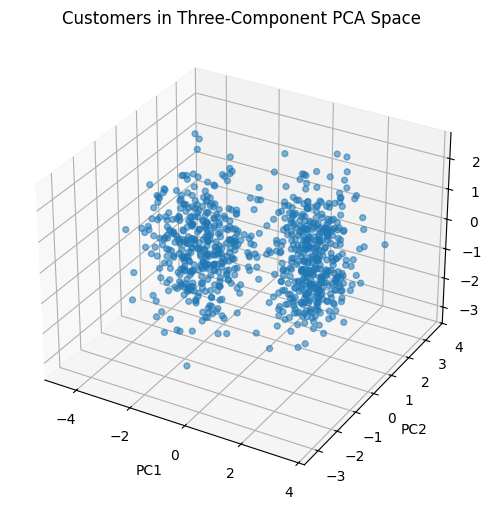

In [ ]:
# Visualizing customers in 3-D PCA space
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(pca_df["PC1"], pca_df["PC2"], pca_df["PC3"], alpha=0.55, s=18)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title("Customers in Three-Component PCA Space")
plt.show()

## Step 3 — K-means clustering (3 marks)

Using the three PCA components, identify **4 customer clusters**. A fixed seed is supplied only so that everyone receives the same reproducible cluster labels; you do not need to choose or interpret the seed.

Use the cluster-size output and 3-D plot to answer **Step 3 in the Word handout**.

In [ ]:
## TODO: Find 4 clusters in this data
K = 4
kmeans = KMeans(n_clusters=K, random_state=10, n_init=20)

## TODO: Use pca representations to obtain clusters
data["Cluster"] = kmeans.fit_predict(X_pca)

cluster_sizes = data["Cluster"].value_counts().sort_index()
cluster_sizes

,count
Cluster,
0,210
1,179
2,191
3,220


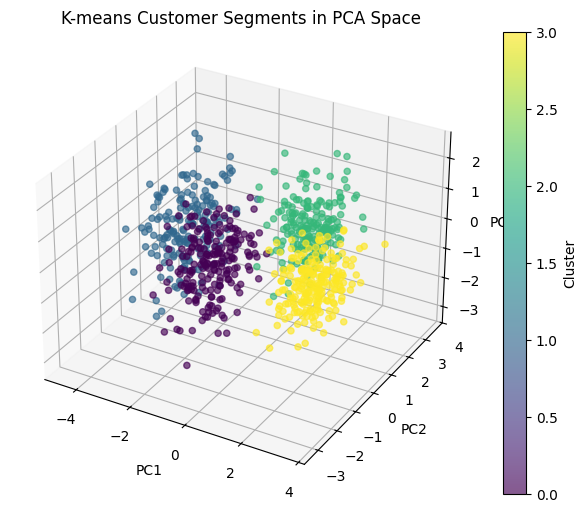

In [ ]:
# Provided visualization: PCA scores colored by cluster
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
scatter = ax.scatter(
    pca_df["PC1"], pca_df["PC2"], pca_df["PC3"],
    c=data["Cluster"], cmap="viridis", alpha=0.65, s=20
)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title("K-means Customer Segments in PCA Space")
fig.colorbar(scatter, ax=ax, label="Cluster")
plt.show()

# Step 4 — Business analysis and managerial recommendations (6 marks)

The cluster number itself has no managerial meaning. Profile the clusters using customer value, promotion responsiveness, and shopping-channel behavior. Use the tables and plots below to answer **Questions 4.1–4.4 in the Word handout**.

### 4.1 Customer value (2 marks)

Create `Monthly_Value = Purchase_Amount × Frequency_of_Purchase` and compare the value-related measures across clusters. The provided box plot shows the **customer-level distribution** of `Monthly_Value` within each cluster.

Use the table and box plot to answer **4.1 in the Word handout** and paste the requested screenshot there.

In [ ]:
## TODO: create Monthly_Value and the cluster-level value profile
data["Monthly_Value"] = data["Purchase_Amount"] * data["Frequency_of_Purchase"]

value_profile = data.groupby("Cluster")[["Age","Income_Score",
    "Purchase_Amount",
    "Frequency_of_Purchase",
    "Monthly_Value",
    "Brand_Loyalty",
    "Customer_Satisfaction",
]].mean().round(2)

value_profile

,Age,Income_Score,Purchase_Amount,Frequency_of_Purchase,Monthly_Value,Brand_Loyalty,Customer_Satisfaction
Cluster,,,,,,,
0,27.04,1.91,241.17,7.98,1925.80,2.39,7.10
1,33.12,1.66,118.50,2.75,331.86,1.94,5.48
2,45.12,2.47,302.83,5.45,1659.15,4.10,8.14
3,38.74,2.78,419.77,9.41,3948.76,4.39,8.75


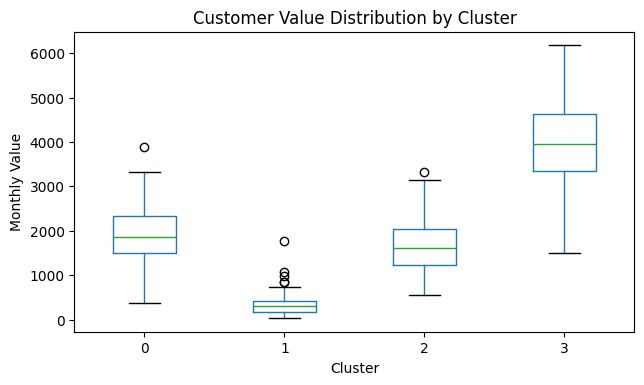

In [ ]:
# Simple box plot: customer-level Monthly_Value by cluster
ax = data.boxplot(column="Monthly_Value", by="Cluster", figsize=(7, 4), grid=False)
ax.set_ylabel("Monthly Value")
ax.set_title("Customer Value Distribution by Cluster")
plt.suptitle("")
plt.show()

### 4.2 Promotion and advertising responsiveness (2 marks)

`Engagement_with_Ads` and `Discount_Sensitivity` are ordinal categories, so the provided code maps them to ordered numeric scores for visualization. It also reports discount-use and loyalty-program membership rates.

Use the promotion-profile table and the two box plots to answer **4.2 in the Word handout** and paste the requested screenshots there.

,Ad_Engagement_Score,Discount_Used_Flag,Discount_Sensitivity_Score,Loyalty_Member_Flag
Cluster,,,,
0,2.590,0.852,1.624,0.376
1,0.665,0.508,1.128,0.201
2,0.990,0.241,0.408,0.665
3,1.564,0.245,0.395,0.791


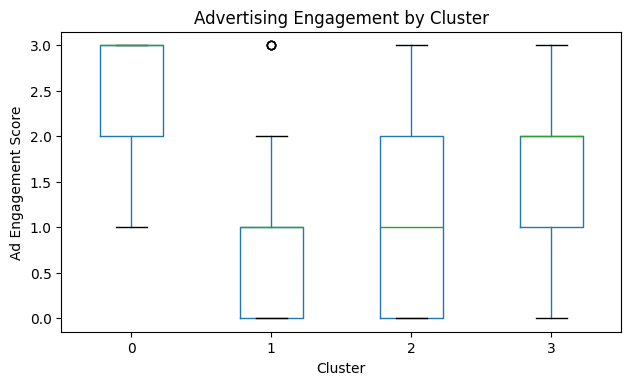

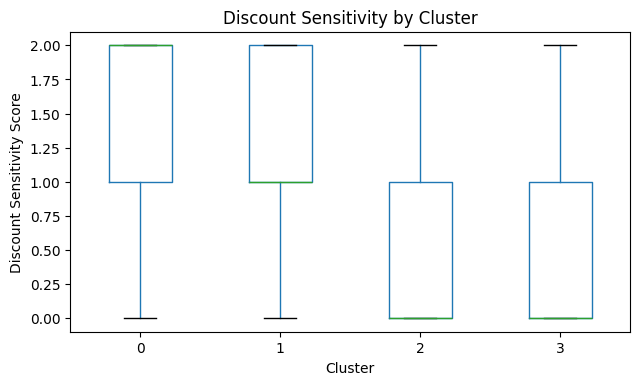

In [ ]:
# Prepare promotion-response measures
data["Discount_Used_Flag"] = data["Discount_Used"].astype(int)
data["Loyalty_Member_Flag"] = data["Customer_Loyalty_Program_Member"].astype(int)

ad_map = {"No Engagement": 0, "Low": 1, "Medium": 2, "High": 3}
discount_map = {"Not Sensitive": 0, "Somewhat Sensitive": 1, "Very Sensitive": 2}

data["Ad_Engagement_Score"] = data["Engagement_with_Ads"].map(ad_map)
data["Discount_Sensitivity_Score"] = data["Discount_Sensitivity"].map(discount_map)

promotion_profile = data.groupby("Cluster")[[
    "Ad_Engagement_Score",
    "Discount_Used_Flag",
    "Discount_Sensitivity_Score",
    "Loyalty_Member_Flag",
]].mean().round(3)

display(promotion_profile)

# Box plot 1: advertising engagement
ax = data.boxplot(column="Ad_Engagement_Score", by="Cluster", figsize=(7, 4), grid=False)
ax.set_ylabel("Ad Engagement Score")
ax.set_title("Advertising Engagement by Cluster")
plt.suptitle("")
plt.show()

# Box plot 2: discount sensitivity
ax = data.boxplot(column="Discount_Sensitivity_Score", by="Cluster", figsize=(7, 4), grid=False)
ax.set_ylabel("Discount Sensitivity Score")
ax.set_title("Discount Sensitivity by Cluster")
plt.suptitle("")
plt.show()

### 4.3 Shopping-channel preferences (1 mark)

For nominal categories such as purchase channel, device, and shipping preference, use normalized cross-tabulations for exact within-cluster shares and simple **count plots** for visual comparison.

Use the outputs below to answer **4.3 in the Word handout** and paste the requested count-plot screenshot(s) there.

Purchase_Channel,In-Store,Mixed,Online
Cluster,,,
0,0.043,0.195,0.762
1,0.419,0.374,0.207
2,0.733,0.204,0.063
3,0.164,0.568,0.268


Device_Used_for_Shopping,Desktop,Smartphone,Tablet
Cluster,,,
0,0.148,0.733,0.119
1,0.251,0.447,0.302
2,0.445,0.199,0.356
3,0.223,0.459,0.318


Shipping_Preference,Express,No Preference,Standard
Cluster,,,
0,0.352,0.219,0.429
1,0.106,0.497,0.397
2,0.199,0.340,0.461
3,0.441,0.218,0.341


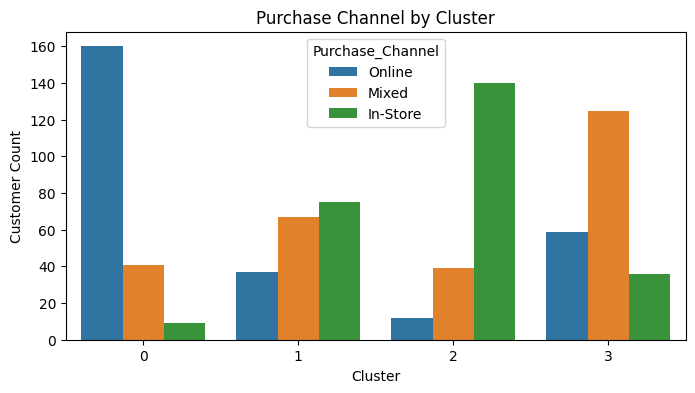

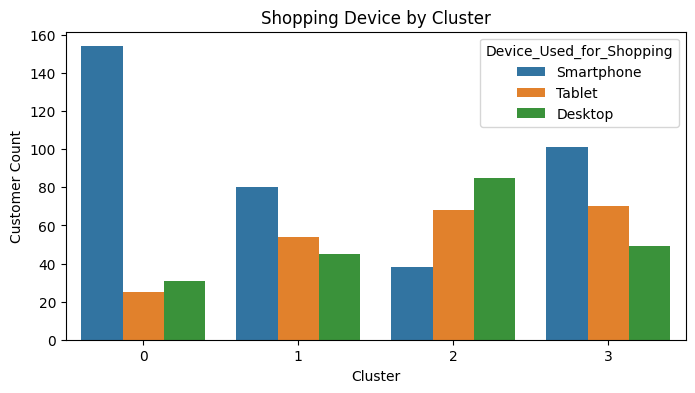

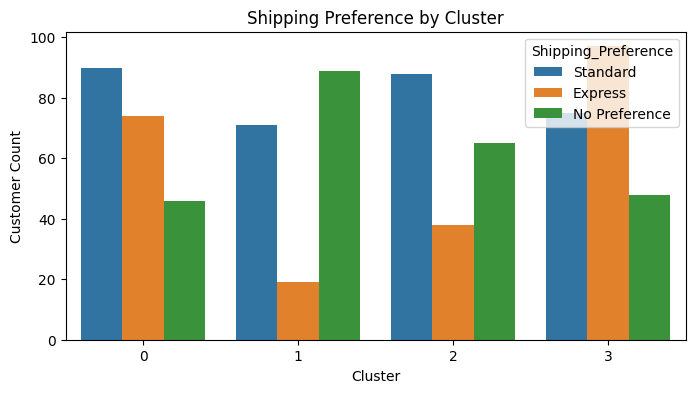

In [ ]:
# Normalized shares support the interpretation
channel_profile = pd.crosstab(
    data["Cluster"], data["Purchase_Channel"], normalize="index"
).round(3)
device_profile = pd.crosstab(
    data["Cluster"], data["Device_Used_for_Shopping"], normalize="index"
).round(3)
shipping_profile = pd.crosstab(
    data["Cluster"], data["Shipping_Preference"], normalize="index"
).round(3)

display(channel_profile)
display(device_profile)
display(shipping_profile)

# Simple count plots
plt.figure(figsize=(8, 4))
sns.countplot(data=data, x="Cluster", hue="Purchase_Channel")
plt.title("Purchase Channel by Cluster")
plt.ylabel("Customer Count")
plt.show()

plt.figure(figsize=(8, 4))
sns.countplot(data=data, x="Cluster", hue="Device_Used_for_Shopping")
plt.title("Shopping Device by Cluster")
plt.ylabel("Customer Count")
plt.show()

plt.figure(figsize=(8, 4))
sns.countplot(data=data, x="Cluster", hue="Shipping_Preference")
plt.title("Shipping Preference by Cluster")
plt.ylabel("Customer Count")
plt.show()